# FruitCount — Pipeline Kaggle lấy source từ GitHub

Giữ nguyên pipeline chuẩn bị dữ liệu, huấn luyện, resume checkpoint, đánh giá và so sánh của kaggle_pipeline.ipynb.

Trước khi chạy:
1. Commit và push source lên nhánh TLuan của repository GitHub.
2. Bật Internet và GPU trong Settings của notebook Kaggle.
3. Add Input bộ MinneApple và sửa đường dẫn ảnh/mask ở cell cấu hình dữ liệu.

Source được clone vào /kaggle/working/FruitCountGit. Không cần upload source thành Kaggle Dataset.
Checkpoint được lưu vào /kaggle/working/runs sau mỗi epoch. Khi đổi phiên, cần lưu output phiên trước và khôi phục runs để resume.
Clone đã có được dùng lại, không tự pull. Muốn lấy code mới, dùng phiên mới hoặc đổi WORK sang thư mục chưa tồn tại.


In [1]:
import os, shutil, sys, subprocess
from pathlib import Path

REPO_URL = 'https://github.com/QNhut/BTL_CV.git'
BRANCH = 'TLuan'
WORK = '/kaggle/working/FruitCountGit'

work_dir = Path(WORK)
if not work_dir.exists():
    subprocess.run(
        ['git', 'clone', '--branch', BRANCH, '--single-branch', REPO_URL, WORK],
        check=True,
    )
else:
    if not (work_dir / '.git').is_dir():
        raise RuntimeError(f'{WORK} exists but is not a Git checkout. Choose another WORK directory.')
    current_branch = subprocess.check_output(
        ['git', '-C', WORK, 'branch', '--show-current'], text=True
    ).strip()
    if current_branch != BRANCH:
        raise RuntimeError(f'Existing checkout uses {current_branch}, expected {BRANCH}. Choose another WORK directory.')

for required in ('src', 'scripts/train.py', 'configs/dataset.yaml', 'requirements.txt'):
    if not (work_dir / required).exists():
        raise FileNotFoundError(f'Missing project file: {required}')

os.chdir(WORK)
if WORK not in sys.path:
    sys.path.insert(0, WORK)
print('Source:', REPO_URL, '| branch:', BRANCH)
subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
subprocess.run([sys.executable, '-c', "import torch; print('torch', torch.__version__, '| cuda', torch.cuda.is_available())"], check=True)


Source: https://github.com/QNhut/BTL_CV.git | branch: TLuan
cbee25c
torch 2.11.0+cu128 | cuda True


CompletedProcess(args=['/usr/bin/python3', '-c', "import torch; print('torch', torch.__version__, '| cuda', torch.cuda.is_available())"], returncode=0)

## 1. Cấu hình dữ liệu
Sửa đường dẫn cho đúng cấu trúc bộ dữ liệu bạn Add vào (xem `/kaggle/input`).

In [2]:
from src.utils import load_yaml, save_yaml
from pathlib import Path

ds = load_yaml('configs/dataset.yaml')
# Set both paths explicitly if more than one dataset is attached.
IMAGES_DIR = None
MASKS_DIR = None
if IMAGES_DIR is None or MASKS_DIR is None:
    candidates = [p for p in Path('/kaggle/input').rglob('images')
                  if p.is_dir() and (p.parent / 'masks').is_dir()
                  and 'test' not in p.parts and 'val' not in p.parts]
    train_candidates = [p for p in candidates if 'train' in p.parts]
    candidates = train_candidates or candidates
    if len(candidates) != 1:
        raise ValueError(f'Set IMAGES_DIR and MASKS_DIR explicitly. Found image/mask pairs: {candidates}')
    IMAGES_DIR = str(candidates[0])
    MASKS_DIR = str(candidates[0].parent / 'masks')
for folder in (IMAGES_DIR, MASKS_DIR):
    if not Path(folder).is_dir():
        raise FileNotFoundError(f'Dataset directory does not exist: {folder}')
ds['paths']['images_dir'] = IMAGES_DIR
ds['paths']['masks_dir'] = MASKS_DIR
ds['processed_dir'] = '/kaggle/working/processed'
save_yaml(ds, 'configs/dataset.yaml')
print(ds['paths'])


{'images_dir': '/kaggle/input/datasets/nhtnguye/dataminesapple/detection/detection/train/images', 'masks_dir': '/kaggle/input/datasets/nhtnguye/dataminesapple/detection/detection/train/masks', 'mask_suffix': '', 'labels_dir': None, 'coco_json': None}


In [3]:
import subprocess
import shlex
import sys

def run_python(arguments):
    subprocess.run([sys.executable, *shlex.split(arguments)], check=True)

run_python('scripts/prepare_data.py')


13:54:59 | train  470 ảnh | quả/ảnh: min=1  TB=42.2  max=121 | tổng=19837
13:54:59 | val    100 ảnh | quả/ảnh: min=1  TB=41.8  max=123 | tổng=4180
13:54:59 | test   100 ảnh | quả/ảnh: min=3  TB=41.6  max=117 | tổng=4159
13:55:02 | Đã xuất dataset YOLO: /kaggle/working/processed/yolo/data.yaml
13:55:02 | Đã lưu records/splits vào /kaggle/working/processed


## 2. Huấn luyện
Kaggle giới hạn ~9–12 giờ/phiên và có thể ngắt; `--resume` tiếp tục từ `last.pt`. Chạy từng model ở các cell/phiên riêng nếu cần.

In [4]:
MODELS = ['yolov8']          # thêm: , 'csrnet', 'yolo11', 'faster_rcnn', 'mask_rcnn'

EPOCHS = 2                          # ví dụ 5 để chạy thử nhanh

from pathlib import Path

# Checkpoints are saved after each epoch by the training code.
# To resume in a new Kaggle session, restore previous runs here first.
RUNS = Path('/kaggle/working/runs')
for m in MODELS:
    cfg = load_yaml(f'configs/models/{m}.yaml')
    checkpoint = RUNS / cfg['name'] / 'weights' / 'last.pt'
    resume = '--resume' if checkpoint.is_file() else ''
    extra = f'--epochs {EPOCHS}' if EPOCHS else ''
    print(f'{m}: resume {checkpoint}' if resume else f'{m}: start training')
    run_python(f'scripts/train.py --model configs/models/{m}.yaml --out {RUNS} {extra} {resume}')


yolov8: resume /kaggle/working/runs/yolov8s/weights/last.pt
Ultralytics 8.4.180 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/processed/yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/runs/yolov8s/weights/last.pt, moment

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      14/40       5.9G       1.56     0.7654     0.9416        577       1024: 100% ━━━━━━━━━━━━ 59/59 4.1it/s 14.2s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.8it/s 1.5s0.3s
                   all        100       4180      0.834      0.779      0.867      0.451

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      15/40      6.33G      1.655     0.8029     0.9667        253       1024: 100% ━━━━━━━━━━━━ 59/59 4.0it/s 14.8s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.4it/s 1.6s0.3s
                   all        100       4180       0.85        0.8      0.886      0.469

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      16/40      6.33G      1.663     0.8058     0.9729        540       1024: 100% ━

14:03:36 | Xong. Trọng số tốt nhất: /kaggle/working/runs/yolov8s/weights/best.pt


## 3. Đánh giá trên tập test

In [10]:
for m in MODELS:
    run_python(f'scripts/evaluate.py --model configs/models/{m}.yaml --out /kaggle/working/runs --split test --speed')

# YOLO + tiling (SAHI-style)
run_python(f'scripts/evaluate.py --model configs/models/yolov8.yaml --out /kaggle/working/runs --split test --tile --tag _tile')


14:21:31 | yolov8s: MAE=3.07 RMSE=4.73 MAPE=8.5% R2=0.972 mAP50=0.896 mAP50-95=0.485 FPS=33.1
14:21:31 | Đã ghi kết quả vào /kaggle/working/runs/yolov8s
14:22:18 | yolov8s: MAE=4.47 RMSE=6.36 MAPE=13.0% R2=0.950 mAP50=0.840 mAP50-95=0.441
14:22:18 | Đã ghi kết quả vào /kaggle/working/runs/yolov8s


In [11]:
run_python(f'scripts/compare.py --runs /kaggle/working/runs --split test')

import pandas as pd
comparison = pd.read_csv('/kaggle/working/runs/comparison/comparison_test.csv')
pd.set_option('display.max_columns', None)
from IPython.display import display
display(comparison.style.format(precision=3, na_rep='\u2014').set_caption(
    'Accuracy / Precision / Recall / F1 / mAP: 0-1; MAPE: %; latency: ms. '
    'Precision and Recall at best F1 (IoU 0.5).'
))

14:22:21 | 
| model | family | mae | rmse | mape_pct | r2 | map50 | map | fps | params_million |
|---|---|---|---|---|---|---|---|---|---|
| yolov8s | detection | 3.070 | 4.734 | 8.518 | 0.972 | 0.896 | 0.485 | 33.060 | 11.136 |
| yolov8s (tile) | detection | 4.470 | 6.357 | 13.023 | 0.950 | 0.840 | 0.441 | - | - |
14:22:21 | Đã ghi bảng và biểu đồ vào /kaggle/working/runs/comparison


,model,family,mae,rmse,mape_pct,r2,map50,map,fps,params_million
0,yolov8s,detection,3.070,4.734,8.518,0.972,0.896,0.485,33.060,11.136
1,yolov8s (tile),detection,4.470,6.357,13.023,0.950,0.840,0.441,—,—


## 4. Phân tích: quả chồng lấn nhiều thì model nào đếm tốt hơn?

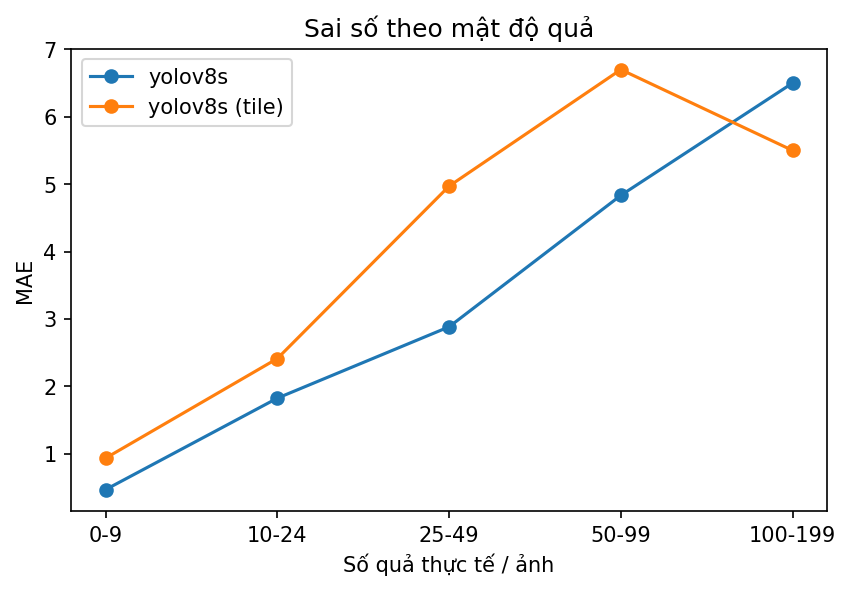

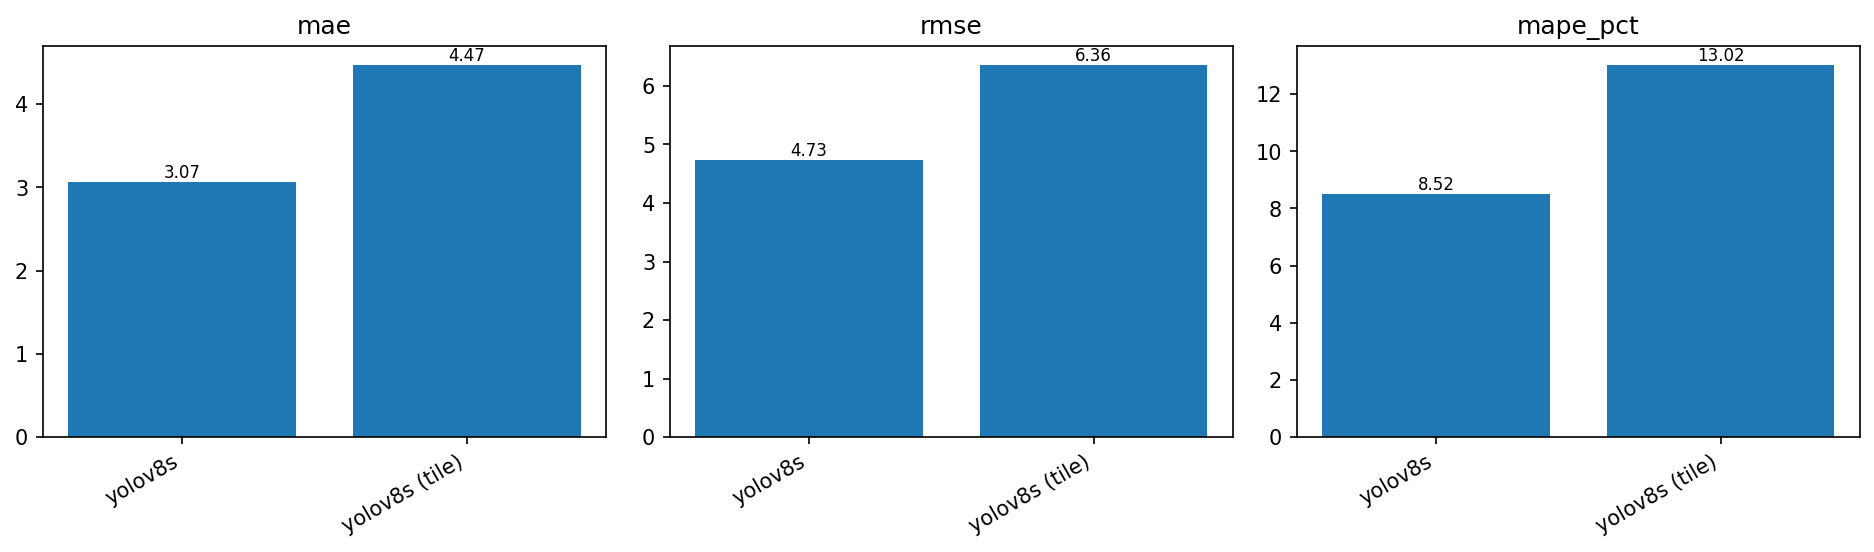

In [12]:
from IPython.display import Image, display
display(Image('/kaggle/working/runs/comparison/error_by_count_test.png'))
display(Image('/kaggle/working/runs/comparison/comparison_test.png'))

## 5. Ví dụ minh họa (cho báo cáo)

In [8]:
import glob, random
from src.data import load_split_records

test = load_split_records('/kaggle/working/processed', 'test')
samples = random.Random(0).sample(test, min(4, len(test)))
os.makedirs('/kaggle/working/samples', exist_ok=True)
for r in samples:
    shutil.copy(r.image_path, f'/kaggle/working/samples/{r.image_id}.png')
    print(r.image_id, 'GT =', r.count)

for m in MODELS:
    run_python(f'scripts/predict.py --model configs/models/{m}.yaml --runs /kaggle/working/runs --source /kaggle/working/samples')


20150921_131453_image66 GT = 35
20150921_132245_image396 GT = 22
20150921_131625_image1056 GT = 45
20150919_174151_image301 GT = 109


14:04:57 | 20150919_174151_image301.png   -> 110 quả
14:04:57 | 20150921_131453_image66.png    -> 40 quả
14:04:57 | 20150921_131625_image1056.png  -> 56 quả
14:04:58 | 20150921_132245_image396.png   -> 38 quả
14:04:58 | Tổng: 4 ảnh, 244 quả. Kết quả: /kaggle/working/vis/yolov8


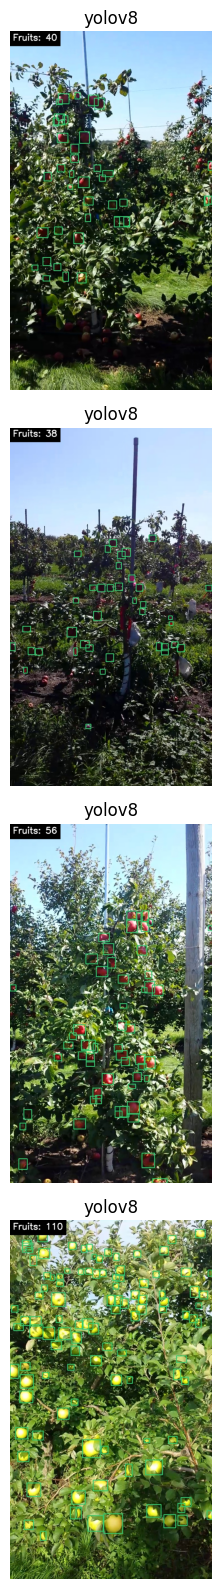

In [9]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg

ids = [r.image_id for r in samples]
fig, axes = plt.subplots(len(ids), len(MODELS), figsize=(6 * len(MODELS), 4 * len(ids)), squeeze=False)
for i, iid in enumerate(ids):
    for j, m in enumerate(MODELS):
        model_name = load_yaml(f'configs/models/{m}.yaml')['name']
        axes[i][j].imshow(mpimg.imread(f'/kaggle/working/runs/{model_name}/predictions/{iid}_count.jpg'))
        axes[i][j].set_title(m); axes[i][j].axis('off')
plt.tight_layout(); plt.show()